# What is a business cycle? A data science exercise

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mhaabeth/Econ-4310/blob/main/business_cycle_pca.ipynb)

ECON4310, University of Oslo.

1. Download 12 US macroeconomic time series from FRED, 1976 to today.
2. Compute quarterly growth rates.
3. Use principal component analysis (PCA) to find the single variable that best tracks all twelve.
4. Compare it with each series and with NBER recession dates.

The choice of series is subjective. Add your own.

In [1]:
# Setup for Google Colab: fetch the course files (data snapshot). Does nothing elsewhere.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("data"):
    os.system("git clone -q https://github.com/mhaabeth/Econ-4310.git")
    os.chdir("Econ-4310")

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7, 3.8),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
})
BLUE, RED, GREY = "#1f4e9c", "#c0392b", "#7f7f7f"
os.makedirs("figures", exist_ok=True)

## 1. Data

Each series: FRED code, label, and whether it is a level (we take log changes) or a rate (we take changes). Taking logs of the federal funds rate makes no sense when it is close to zero.

Monthly series are averaged to quarters.

In [3]:
series = pd.DataFrame([
    # code,              label,                       group,   transform
    ("GDPC1",            "Real GDP",                  "real",  "log"),
    ("PCECC96",          "Real consumption",          "real",  "log"),
    ("GPDIC1",           "Real private investment",   "real",  "log"),
    ("GCEC1",            "Real government spending",  "real",  "log"),
    ("UNRATE",           "Unemployment rate",         "real",  "diff"),
    ("AWHMAN",           "Weekly hours, manufacturing", "real", "log"),
    ("UMCSENT",          "Consumer sentiment",        "other", "log"),
    ("FEDFUNDS",         "Federal funds rate",        "other", "diff"),
    ("M2SL",             "M2 money stock",            "other", "log"),
    ("CPIAUCSL",         "Consumer prices (CPI)",     "other", "log"),
    ("SPASTT01USM661N",  "Stock prices",              "other", "log"),
    ("USSTHPI",          "House prices",              "other", "log"),
], columns=["code", "label", "group", "transform"]).set_index("code")
series

,label,group,transform
code,,,
GDPC1,Real GDP,real,log
PCECC96,Real consumption,real,log
GPDIC1,Real private investment,real,log
GCEC1,Real government spending,real,log
UNRATE,Unemployment rate,real,diff
AWHMAN,"Weekly hours, manufacturing",real,log
UMCSENT,Consumer sentiment,other,log
FEDFUNDS,Federal funds rate,other,diff
M2SL,M2 money stock,other,log


In [4]:
def fred_quarterly(code, start="1976-01-01"):
    url = ("https://fred.stlouisfed.org/graph/fredgraph.csv"
           f"?id={code}&cosd={start}&fq=Quarterly&fam=avg")
    raw = pd.read_csv(url, na_values=".")
    s = pd.Series(raw.iloc[:, 1].values, index=pd.PeriodIndex(pd.to_datetime(raw.iloc[:, 0]), freq="Q"))
    return pd.to_numeric(s, errors="coerce").rename(code)

try:
    data = pd.concat([fred_quarterly(c) for c in list(series.index) + ["USREC"]], axis=1)
    source = "FRED"
except Exception as err:
    data = pd.read_csv("data/fred_snapshot.csv", index_col=0)
    data.index = pd.PeriodIndex(data.index, freq="Q")
    source = f"snapshot in data/ (FRED unavailable: {type(err).__name__})"

print(f"Source: {source}. {data.index[0]} to {data.index[-1]}.")
data.tail()

Source: snapshot in data/ (FRED unavailable: URLError). 1976Q1 to 2026Q2.


,GDPC1,PCECC96,GPDIC1,GCEC1,USSTHPI,UNRATE,AWHMAN,FEDFUNDS,M2SL,CPIAUCSL,SPASTT01USM661N,UMCSENT,USREC
quarter,,,,,,,,,,,,,
2025Q2,23884.563,16378.319,4464.421,4083.655,698.69,4.200000,40.966667,4.330000,21849.833333,320.785667,181.390867,55.033333,0.0
2025Q3,24112.966,16526.176,4472.599,4099.823,703.04,4.333333,41.033333,4.293333,22098.100000,323.235000,195.955533,58.333333,0.0
2025Q4,24125.479,16604.582,4484.686,4040.531,707.22,4.450000,41.166667,3.896667,22294.966667,325.547000,202.736567,52.500000,0.0
2026Q1,24274.383,16634.157,4563.036,4087.452,712.20,4.333333,41.500000,3.640000,22550.800000,328.113667,212.832233,55.433333,0.0
2026Q2,24408.011,16788.685,4615.141,4086.608,719.87,4.266667,41.633333,3.633333,22961.733333,332.984667,216.502133,48.033333,0.0


## 2. Growth rates

Log changes ×100 ≈ percent growth per quarter. Changes in percentage points for the two rates.

In [5]:
growth = pd.DataFrame({
    c: 100 * np.log(data[c]).diff() if series.loc[c, "transform"] == "log" else data[c].diff()
    for c in series.index
}).dropna()
print(f"{growth.index[0]} to {growth.index[-1]}: {len(growth)} quarters")
growth.describe().T.round(2)

1976Q2 to 2026Q2: 201 quarters


,count,mean,std,min,25%,50%,75%,max
GDPC1,201.0,0.67,1.06,-8.20,0.36,0.73,1.03,7.48
PCECC96,201.0,0.72,1.08,-9.05,0.40,0.73,1.07,8.52
GPDIC1,201.0,0.91,3.72,-15.02,-0.71,0.79,2.87,17.15
GCEC1,201.0,0.43,0.84,-1.72,-0.07,0.44,0.91,2.48
UNRATE,201.0,-0.02,0.79,-4.20,-0.20,-0.07,0.07,9.17
AWHMAN,201.0,0.02,0.73,-5.21,-0.25,0.00,0.32,4.32
UMCSENT,201.0,-0.28,6.90,-26.60,-3.50,-0.27,3.38,22.03
FEDFUNDS,201.0,-0.01,0.84,-3.99,-0.20,0.00,0.25,6.02
M2SL,201.0,1.54,1.20,-1.70,0.97,1.48,1.95,12.45
CPIAUCSL,201.0,0.89,0.74,-2.32,0.53,0.78,1.08,3.87


## 3. Principal component analysis

Standardize each growth rate to mean 0 and standard deviation 1, so no series dominates because of its units. Stack them in a $T \times 12$ matrix $Z$.

The first principal component is the weighted average $f_t = Z_t w$ with weights $w$ (with $\|w\| = 1$) chosen to maximize the variance of $f_t$. Equivalently, $w$ is the first eigenvector of the correlation matrix of the twelve series. No economic theory goes in.

COVID-19 produced quarterly movements ten times larger than anything before. To keep two quarters from driving the weights, we estimate $w$ on 1976–2019 and then apply it to the full sample.

In [6]:
est = growth.loc[:"2019Q4"]
mu, sd = est.mean(), est.std()
Z_est = (est - mu) / sd
Z = (growth - mu) / sd                       # full sample, same standardization

eigval, eigvec = np.linalg.eigh(Z_est.corr().values)
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]

w = pd.Series(eigvec[:, 0], index=series.index)
if w["GDPC1"] < 0:                           # sign is arbitrary: make the factor move with GDP
    w = -w

pc1 = Z @ w
pc1 = (pc1 - pc1.loc[:"2019Q4"].mean()) / pc1.loc[:"2019Q4"].std()

share = eigval / eigval.sum()
print(f"First component explains {share[0]:.0%} of the variance of the 12 series "
      f"(second: {share[1]:.0%}, third: {share[2]:.0%}).")

First component explains 31% of the variance of the 12 series (second: 13%, third: 12%).


In [7]:
summary = pd.DataFrame({
    "Weight": w.round(2),
    "Corr. with PC1, 1976–2019": Z_est.corrwith(pc1.loc[:"2019Q4"]).round(2),
}).set_index(series["label"])
summary

,Weight,"Corr. with PC1, 1976–2019"
label,,
Real GDP,0.47,0.90
Real consumption,0.34,0.65
Real private investment,0.42,0.81
Real government spending,-0.01,-0.01
Unemployment rate,-0.41,-0.79
"Weekly hours, manufacturing",0.36,0.69
Consumer sentiment,0.19,0.38
Federal funds rate,0.28,0.54
M2 money stock,-0.09,-0.18


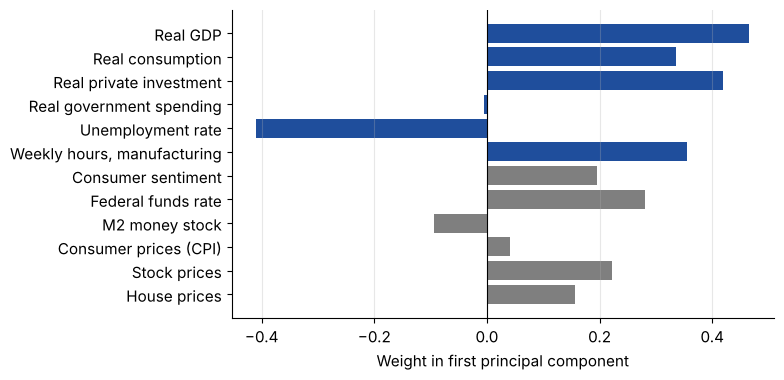

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
lab = series["label"]
colors = [BLUE if g == "real" else GREY for g in series["group"]]
ax.barh(lab[::-1], w[::-1], color=colors[::-1])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Weight in first principal component")
ax.grid(axis="y", visible=False)
fig.savefig("figures/pca_weights.pdf")
plt.show()

## 4. Plot the result

Each panel shows one standardized growth rate and the first principal component. 1976–2019; the COVID quarters would squash everything else.

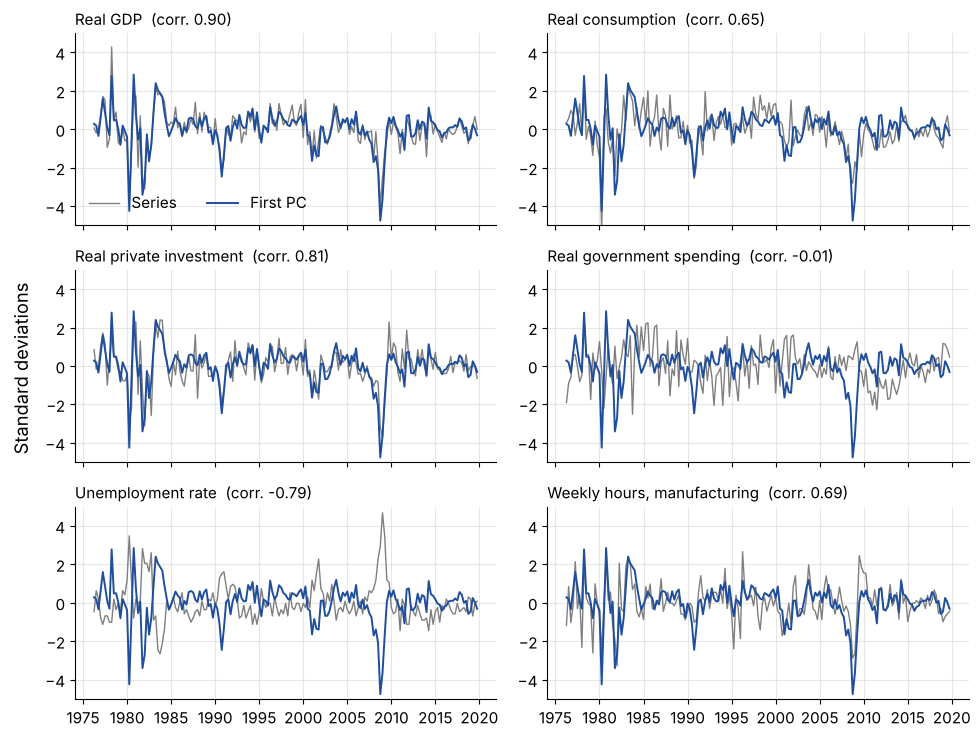

In [9]:
def panel_plot(group, fname):
    codes = series.index[series["group"] == group]
    fig, axes = plt.subplots(3, 2, figsize=(10, 7.5), sharex=True)
    for ax, c in zip(axes.flat, codes):
        t = Z.loc[:"2019Q4"].index.to_timestamp()
        ax.plot(t, Z.loc[:"2019Q4", c], color=GREY, lw=1, label="Series")
        ax.plot(t, pc1.loc[:"2019Q4"], color=BLUE, lw=1.4, label="First PC")
        r = Z_est[c].corr(pc1.loc[:"2019Q4"])
        ax.set_title(f"{series.loc[c, 'label']}  (corr. {r:.2f})", loc="left", fontsize=11)
        ax.set_ylim(-5, 5)
    axes[0, 0].legend(frameon=False, loc="lower left", ncol=2)
    fig.supylabel("Standard deviations")
    fig.tight_layout()
    fig.savefig(fname)
    plt.show()

panel_plot("real", "figures/real_pca.pdf")

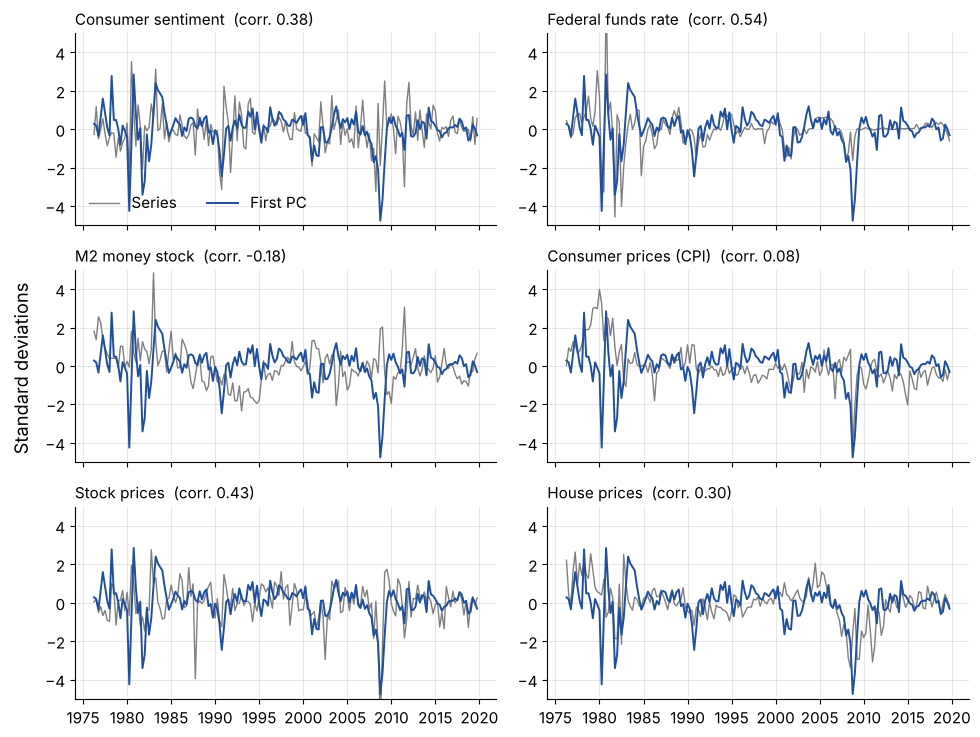

In [10]:
panel_plot("other", "figures/rest_pca.pdf")

## 5. NBER recessions

The NBER Business Cycle Dating Committee decides when US recessions start and end. It looks at many indicators and uses judgment. Compare its dates (shaded) with the first principal component.

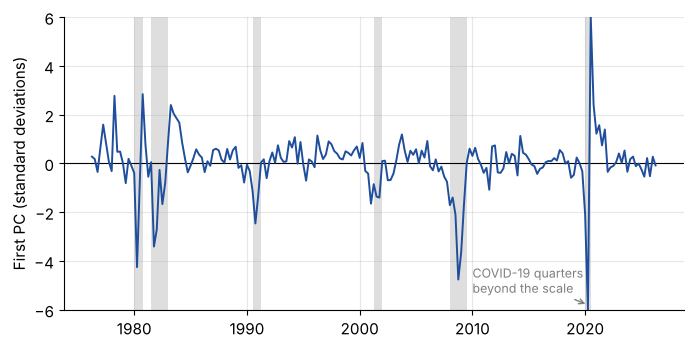

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.8))
t = pc1.index.to_timestamp()
rec = data["USREC"].reindex(pc1.index) > 0
for start, in_rec in zip(t, rec):
    if in_rec:
        ax.axvspan(start, start + pd.offsets.QuarterEnd(0), color=GREY, alpha=0.25, lw=0)
ax.axhline(0, color="k", lw=0.8)
ax.plot(t, pc1.clip(-6, 6), color=BLUE, lw=1.4)
ax.set_ylabel("First PC (standard deviations)")
ax.set_ylim(-6, 6)
ax.annotate("COVID-19 quarters\nbeyond the scale", xy=(pd.Timestamp("2020-04-01"), -5.8),
            xytext=(pd.Timestamp("2010-01-01"), -5.3), fontsize=9, color=GREY,
            arrowprops=dict(arrowstyle="->", color=GREY))
fig.savefig("figures/nber.pdf")
plt.show()

In [12]:
# How sharply does the first PC separate NBER recession quarters from expansions?
print(pd.DataFrame({"First PC": pc1, "Recession": rec})
      .groupby("Recession")["First PC"].describe()[["count", "mean", "min", "max"]].round(2))

           count  mean    min    max
Recession                           
False      178.0  0.31  -1.65  10.02
True        23.0 -2.47 -16.60   0.05


## References

- Burns, A. F. and Mitchell, W. C. (1946). *Measuring Business Cycles*. NBER.
- Stock, J. H. and Watson, M. W. (2002). Macroeconomic Forecasting Using Diffusion Indexes. *Journal of Business & Economic Statistics*, 20(2), 147–162.
- Stock, J. H. and Watson, M. W. (2016). Dynamic Factor Models, Factor-Augmented Vector Autoregressions, and Structural Vector Autoregressions in Macroeconomics. *Handbook of Macroeconomics*, vol. 2A, 415–525.

Data: FRED, Federal Reserve Bank of St. Louis.